# Week 2: Mechanics and Data Quality
Verify that you can trust the data you downloaded.

In [14]:
import pandas as pd
import yfinance as yf

TICKERS = ["TLT", "SHY"]

tlt = pd.read_csv(f"../data/{TICKERS[0]}.csv", index_col=0, parse_dates=True)
shy = pd.read_csv(f"../data/{TICKERS[1]}.csv", index_col=0, parse_dates=True)

## Visual
Plot three versions of the price for each asset on one chart:

1. **Raw Close**: the price that actually traded that day
2. **Close**: adjusted for splits only
3. **Adj Close**: adjusted for splits and dividends

Yahoo doesn't give you the raw price, because its `Close` is already split-adjusted.
To rebuild it, multiply every price *before* a split by that split's ratio (take the time to learn this code):

    splits = yf.Ticker("TICKER").splits
    splits.index = splits.index.tz_localize(None)
    factor = pd.Series(1.0, index=df.index)
    for date, ratio in splits.items():
        factor[df.index < date] *= ratio
    df["Raw Close"] = df["Close"] * factor

Use `logy=True` when plotting so the lines are readable.

**What to look for:**
- **Splits**: Raw Close drops suddenly while Close and Adj Close don't. If your asset has never split, Raw Close sits exactly on top of Close.
- **Dividends**: Close and Adj Close slowly drift apart. To see this clearly, also plot `df["Adj Close"] / df["Close"]`. It steps up each time a dividend is paid and stays flat at 1.0 for non-payers.

Check what you find against `yf.Ticker("TICKER").actions`, which lists every split and dividend.

In [15]:
splits = yf.Ticker("TLT").splits
splits.index = splits.index.tz_localize(None)
factor = pd.Series(1.0, index=tlt.index)
for date, ratio in splits.items():
    factor[tlt.index < date] *= ratio
tlt["Raw Close"] = tlt["Close"] * factor
cols = ["Adj Close", "Close", "Raw Close"]
tlt[cols].plot(logy=True, title="TLT Prices")


,Adj Close,Close,High,Low,Open,Volume,Raw Close
Date,,,,,,,
2016-01-04,89.580673,121.449997,122.449997,121.320000,121.930000,10591900,121.449997
2016-01-05,89.219246,120.959999,121.500000,120.660004,120.879997,6242600,120.959999
2016-01-06,90.421524,122.589996,122.620003,122.050003,122.300003,8916900,122.589996
2016-01-07,90.583763,122.809998,122.930000,121.790001,122.680000,10202200,122.809998
2016-01-08,90.989479,123.360001,123.470001,122.230003,122.430000,9577200,123.360001


,Dividends
Date,
2002-09-03 00:00:00-04:00,0.373
2002-10-01 00:00:00-04:00,0.343
2002-11-01 00:00:00-05:00,0.389
2002-12-02 00:00:00-05:00,0.389
2002-12-31 00:00:00-05:00,0.446
...,...
2026-06-01 00:00:00-04:00,0.336
2026-07-01 00:00:00-04:00,0.318
2026-08-03 00:00:00-04:00,0.330


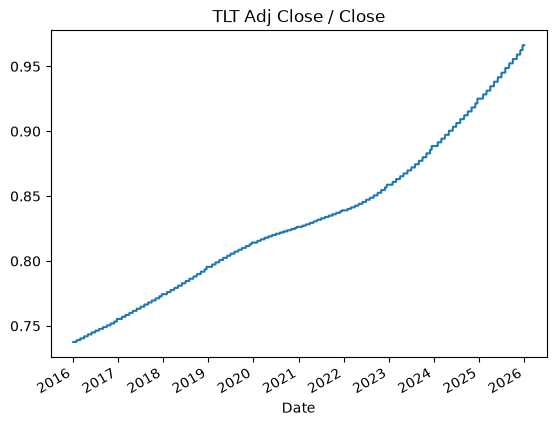

In [18]:
ratio = tlt["Adj Close"] / tlt["Close"]
ratio.plot(title="TLT Adj Close / Close")
yf.Ticker("TLT").actions

## Table
Calculate the **median daily dollar volume** (Close × Volume). Which asset is more liquid?

## Defect checks
Look for missing days, zero-volume days, impossible prices and ticker changes. Then fix what you find in code.

| Defect | Asset | What you found | How your code fixed it |
|---|---|---|---|
| Missing days | [FILL IN] | [FILL IN] | [FILL IN] |
| Zero-volume days | [FILL IN] | [FILL IN] | [FILL IN] |
| Impossible prices | [FILL IN] | [FILL IN] | [FILL IN] |
| Ticker changes | [FILL IN] | [FILL IN] | [FILL IN] |

## The Paragraph
> **Document your defect list and explain how your code fixed them.**

[FILL IN: one paragraph]

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 5: data quality"
git push
```